In [1]:
import socket, os

hostname = socket.gethostname()
if "scg" in hostname:
    BASE_DIR = "/labs/mwinslow/Karen/protein-master/v2_pancan_batch_corrected"
else:
    BASE_DIR = os.path.expanduser("~/Documents/research/scg/protein-master/v2_pancan_batch_corrected")

WORKING_DIR=f"{BASE_DIR}/analysis/01_axis_analysis/bh/axis_sample_scores"

os.chdir(WORKING_DIR)
print(f"📂 Working directory set to: {WORKING_DIR}")

📂 Working directory set to: /Users/karenshih/Documents/research/scg/protein-master/v2_pancan_batch_corrected/analysis/01_axis_analysis/bh/axis_sample_scores


In [2]:
import pandas as pd

In [3]:
complex_scores_df = pd.read_csv(f"{BASE_DIR}/analysis/03_complex/complex_axis_score.csv")

In [4]:
df_long = complex_scores_df.drop(columns=["tmb_bin"]).melt(
    id_vars=["barcode", "cancer_type", "log_mut", "purity"],
    var_name="complex",
    value_name="score"
)

In [5]:
import numpy as np
import pandas as pd
from scipy.stats import pearsonr
from statsmodels.stats.multitest import fdrcorrection

def bootstrap_global_corr(df_long, n_boot=1000, seed=2026):

    np.random.seed(seed)
    results = []

    for complex_name, df_c in df_long.groupby("complex"):

        df_c = df_c.dropna(subset=["score", "log_mut"])

        # observed correlation
        r_obs = pearsonr(df_c["score"], df_c["log_mut"])[0]

        boot_rs = []

        for _ in range(n_boot):

            resampled_list = []

            for cancer, df_sub in df_c.groupby("cancer_type"):

                if len(df_sub) < 5:
                    continue

                sample = df_sub.sample(n=len(df_sub), replace=True)
                resampled_list.append(sample)

            df_boot = pd.concat(resampled_list, axis=0)

            try:
                r = pearsonr(df_boot["score"], df_boot["log_mut"])[0]
                boot_rs.append(r)
            except:
                continue

        boot_rs = np.array(boot_rs)

        # CI
        ci_low = np.percentile(boot_rs, 2.5)
        ci_high = np.percentile(boot_rs, 97.5)

        # --- empirical p-value ---
        # p_lower = np.mean(boot_rs <= 0)
        # p_upper = np.mean(boot_rs > 0)
        # p_boot = 2 * min(p_lower, p_upper)
        k_lower = np.sum(boot_rs <= 0)
        k_upper = np.sum(boot_rs > 0)
        n = len(boot_rs)

        p_boot = 2 * min(
            (k_lower + 1) / (n + 1),
            (k_upper + 1) / (n + 1)
        )

        # avoid exactly 0 (finite sampling)
        # p_boot = max(p_boot, 1 / n_boot)

        results.append({
            "complex": complex_name,
            "r": r_obs,
            "ci_low": ci_low,
            "ci_high": ci_high,
            "p_boot": p_boot,
            "n_samples": len(df_c)
        })

    result_df = pd.DataFrame(results)
    _, result_df["fdr"] = fdrcorrection(result_df["p_boot"])
    
    return pd.DataFrame(results)

In [6]:
global_corr_df = bootstrap_global_corr(df_long, n_boot=1000)

In [7]:
global_corr_df = pd.read_csv(f"{BASE_DIR}/results/tables/fig1/pqc_correlation_summary.csv")

In [ ]:
global_corr_df

,complex,r,ci_low,ci_high,p_boot,n_samples,fdr,category
0,19S Regulatory Particle,0.390798,0.377001,0.406795,0.001998,9104,0.001998,Proteasome
1,20S Core,0.343155,0.327198,0.359902,0.001998,9104,0.001998,Proteasome
2,Cytoplasmic Ribosomes,0.119351,0.100780,0.136820,0.001998,9104,0.001998,Ribosome
3,ER Chaperones,0.294201,0.279016,0.307702,0.001998,9104,0.001998,Chaperone
4,HSP 100,0.291543,0.274331,0.307528,0.001998,9104,0.001998,Chaperone
5,HSP 60,0.334237,0.319119,0.350036,0.001998,9104,0.001998,Chaperone
6,HSP 70,0.291069,0.272151,0.309363,0.001998,9104,0.001998,Chaperone
7,HSP 90,0.263630,0.247167,0.281338,0.001998,9104,0.001998,Chaperone
8,Mitochondrial Ribosomes,0.312645,0.295499,0.329199,0.001998,9104,0.001998,Ribosome


In [8]:
global_corr_df["fdr"] = fdrcorrection(global_corr_df["p_boot"])[1]

In [9]:
global_corr_df["category"] = "Proteasome"

In [11]:
global_corr_df.loc[global_corr_df["complex"].str.contains("HSP|Chap"), "category"] = "Chaperone"

In [12]:
global_corr_df.loc[global_corr_df["complex"].str.contains("Ribo"), "category"] = "Ribosome"

In [13]:
global_corr_df["component"] = "PQC"

In [10]:
corr_boot_df = pd.read_csv(f"{BASE_DIR}/results/tables/fig1/non_pqc_correlation_summary.csv",)

In [15]:
corr_boot_df

,complex,r,ci_low,ci_high,p_boot,n_samples,complex_clean,category
0,antigen_processing_and_presentation,0.276170,0.257584,0.296289,0.0,9104,Antigen processing and presentation,Immune
1,cell_cycle,0.476987,0.465222,0.489162,0.0,9104,Cell cycle,Cell growth and death
2,dna_replication,0.428633,0.415147,0.441970,0.0,9104,DNA replication,DNA replication and repair
3,oxidative_phosphorylation,0.185778,0.167481,0.202928,0.0,9104,Oxidative phosphorylation,Metabolism
4,ribosome_biogenesis_in_eukaryotes,0.424787,0.411859,0.439226,0.0,9104,Ribosome biogenesis in eukaryotes,Translation
5,spliceosome,0.328232,0.312612,0.343203,0.0,9104,Spliceosome,Transcription


In [11]:
corr_boot_df["component"] = "non-PQC"

In [12]:
corr_boot_df.drop(columns="complex",inplace=True)

In [13]:
corr_boot_df["fdr"] = fdrcorrection(corr_boot_df["p_boot"])[1]

In [14]:
corr_boot_df.rename(columns={"complex_clean":"complex"},inplace=True)

In [16]:
global_corr_df = pd.concat([global_corr_df, corr_boot_df])

In [17]:
corr_df_sorted = global_corr_df.sort_values(by=["component","r"], ascending=[False, True])

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


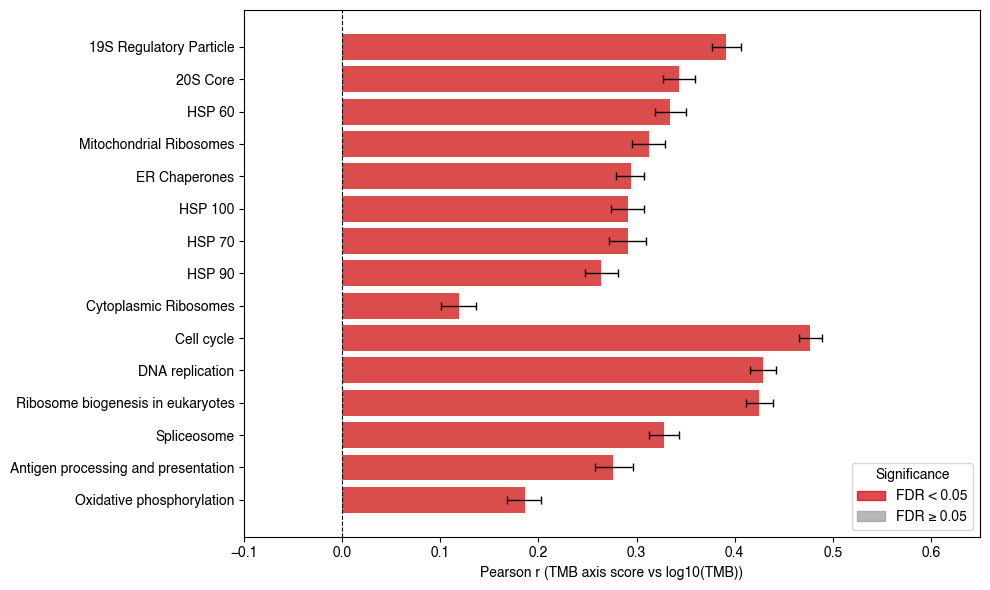

In [ ]:
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import matplotlib as mpl

fig, ax = plt.subplots(figsize=(10,6))

colors = ["#CC0000" if p < 0.05 else "#999999" for p in corr_df_sorted["fdr"]]

ax.barh(corr_df_sorted["complex"], corr_df_sorted["r"], color=colors, alpha=0.7)
ax.errorbar(
    x=corr_df_sorted["r"],
    y=corr_df_sorted["complex"],
    xerr=[
        corr_df_sorted["r"] - corr_df_sorted["ci_low"],
        corr_df_sorted["ci_high"] - corr_df_sorted["r"]
    ],
    fmt="none",
    color="black",
    capsize=3,
    linewidth=1
)

ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
ax.set_xlim(-0.1, 0.65)
ax.set_xlabel("Pearson r (TMB axis score vs log10(TMB))")
# ax.set_ylabel("PQC complexes")
# ax.set_title("Per-cancer correlation: TMB axis score vs TMB")

legend_handles = [
    mpatches.Patch(color="#CC0000", alpha=0.7, label="FDR < 0.05"),
    mpatches.Patch(color="#999999", alpha=0.7, label="FDR ≥ 0.05"),
]
ax.legend(handles=legend_handles, title="Significance", loc="lower right")

plt.tight_layout()
mpl.rcParams["pdf.fonttype"] = 42

plt.savefig(f"{BASE_DIR}/results/figures/main/fig1/fig1c_pqc_correlation_summary_pqc_and_non_pqc.pdf",dpi=300)
plt.show()